# Session 1 practical · ML workflow & data preparation

**ML Bootcamp · Day 1** · <a href="https://colab.research.google.com/github/MusaBangash/Python-Variables/blob/main/ml/bootcamp/session1_practical.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Part A (follow along, ~40 min):** the trainer walks through every step on the **churn** dataset.
**Part B (teams, ~45 min):** you repeat the same steps on **your team's dataset** and fill in the deliverables.

By the end you will have: a problem statement, a checked dataset, an honest train/test split, a baseline score, and a leakage note.

Run cells with **Shift + Enter**. Before each code cell, read the text and **predict** what will happen.

# Part A · Churn, step by step

## A1 · Setup and load

In [1]:
import os
from urllib.request import urlretrieve
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize'] = (8, 4)

BASE = 'https://raw.githubusercontent.com/MusaBangash/Python-Variables/main/ml/data/'
def get(name):
    if not os.path.exists(name):
        urlretrieve(BASE + name, name)
    return name

df = pd.read_csv(get('telco-churn.csv'))
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## A2 · Inspect before you trust

Four checks on every new dataset: **size and types**, **missing values**, **duplicates**, **value ranges**.

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

**Look at the `Dtype` column.** `TotalCharges` is money, but it's stored as text (`object`/`str`). That means some cells are not numbers. Let's find them instead of guessing.

In [3]:
as_number = pd.to_numeric(df['TotalCharges'], errors='coerce')     # text that isn't a number -> NaN
problem = as_number.isna()
print('Cells that are not numbers:', problem.sum())
df.loc[problem, ['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges']]

Cells that are not numbers: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


**Detective work:** all 11 are blank, and every one has `tenure = 0`: brand-new customers who haven't been billed yet. So the true value is **0**, not "the average".

> **Lesson:** before filling a missing value, ask *why* it is missing.

In [4]:
df['TotalCharges'] = as_number.fillna(0)
print('Missing values left:', df.isna().sum().sum())
print('Duplicate rows (ignoring ID):', df.drop(columns='customerID').duplicated().sum())
print('Duplicate IDs:', df.customerID.duplicated().sum())
df.describe()

Missing values left: 0
Duplicate rows (ignoring ID): 22
Duplicate IDs: 0


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


- **22 rows look the same apart from the ID**, but the IDs are all different: they're different customers with identical simple profiles. Keep them. (A true duplicate is the *same* record twice.)
- **Ranges look sensible:** tenure 0–72 months, bills \$18–\$119. No negative ages, no impossible values.

## A3 · Frame the problem

| Part | Our answer |
|---|---|
| Prediction question | Which current customers will cancel next month? |
| Target (y) | `Churn` (Yes/No) → 1/0 |
| Features (X) | every column except `customerID` and `Churn` |
| One row = | one customer |
| Decision | retention team calls the riskiest customers first |
| Task | supervised **classification** |

> We want to predict **Churn** for **each customer** using **their account details available today**, so that **the retention team** can **decide whom to call**. We measure success with **accuracy for now (better metrics in Session 2)** and must beat **the "always stays" baseline**.

## A4 · Target balance: the first number to know

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


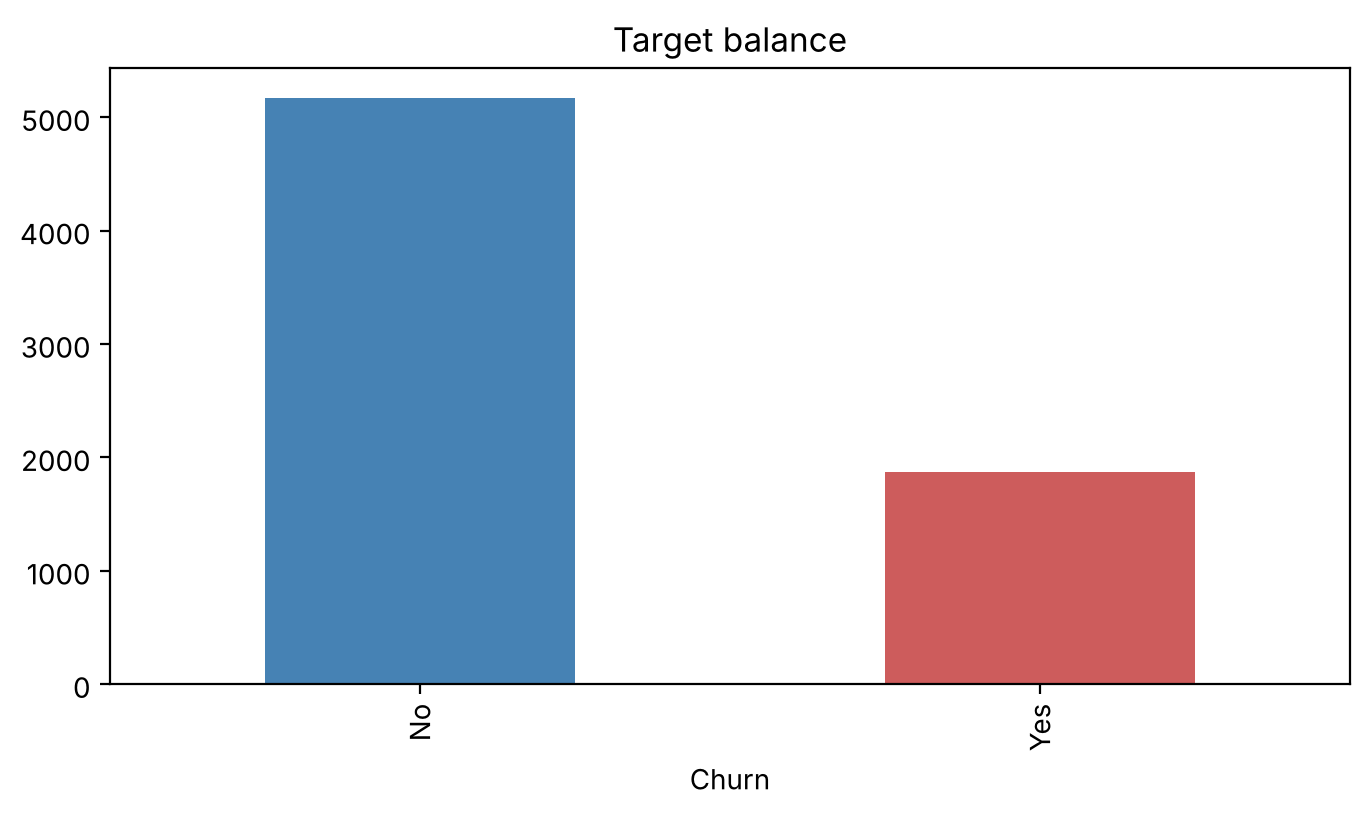

In [5]:
print(df['Churn'].value_counts())
print()
print(df['Churn'].value_counts(normalize=True).round(3))
df['Churn'].value_counts().plot.bar(color=['steelblue', 'indianred'], title='Target balance'); plt.show()

**26.5% churn.** So "always predict stays" is already 73.5% accurate. Any model must beat that.

## A5 · Separate features (X) and target (y)

Drop the ID (a name tag the model could memorise) and the target itself (otherwise the answer is inside the question!).

In [6]:
X = df.drop(columns=['customerID', 'Churn'])
y = (df['Churn'] == 'Yes').astype(int)        # 1 = left, 0 = stayed

numeric_cols = X.select_dtypes(include='number').columns.tolist()
categorical_cols = [c for c in X.columns if c not in numeric_cols]
print('Numeric:', numeric_cols)
print('Categorical:', categorical_cols)

Numeric: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## A6 · Split first, and lock the test set

- `test_size=0.2`: 20% for the final exam.
- `stratify=y`: the same churn rate in both parts.
- `random_state=42`: everybody gets the same split, and we can reproduce it next week.

In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print('Train:', X_train.shape, f'churn {y_train.mean():.3f}')
print('Test: ', X_test.shape, f'churn {y_test.mean():.3f}')

Train: (5634, 19) churn 0.265
Test:  (1409, 19) churn 0.265


**Try it:** change `random_state` to 1, 2, 3 and re-run. The rows change, but the churn rate stays the same, thanks to `stratify`. Remove `stratify=y` and watch it wobble.

## A7 · Leakage, live

### A7a · A column from the future
Imagine the database also had `days_since_last_payment`. Customers who already cancelled stop paying, so the number is large for them. It's **recorded after** the outcome. We simulate it and see what happens.

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

def make_model(num_cols, cat_cols):
    pre = ColumnTransformer([
        ('num', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), num_cols),
        ('cat', make_pipeline(SimpleImputer(strategy='most_frequent'), OneHotEncoder(handle_unknown='ignore')), cat_cols)])
    return make_pipeline(pre, LogisticRegression(max_iter=2000))

honest = make_model(numeric_cols, categorical_cols).fit(X_train, y_train)
print(f'Honest features:          {accuracy_score(y_test, honest.predict(X_test)):.3f}')

rng = np.random.default_rng(0)
leak = pd.Series(np.where(y == 1, rng.normal(45, 15, len(y)), rng.normal(15, 10, len(y))).clip(0).round(), index=X.index)
leaky = make_model(numeric_cols + ['days_since_last_payment'], categorical_cols)
leaky.fit(X_train.assign(days_since_last_payment=leak[X_train.index]), y_train)
print(f'+ days_since_last_payment: {accuracy_score(y_test, leaky.predict(X_test.assign(days_since_last_payment=leak[X_test.index]))):.3f}   <- too good to be true')

Honest features:          0.806


+ days_since_last_payment: 0.934   <- too good to be true


A jump from ~80% to ~93%. But on the day we predict, the customer hasn't cancelled yet, so this column **doesn't exist yet**. In production the model would collapse.

**The test:** *would I know this value at the moment I make the prediction?* If not, it's not a feature.

### A7b · Fitting before splitting
`fit` learns something from data. If we fit on **all** rows, the test rows influence what is learned:

In [9]:
print('Mean tenure learned from ALL rows:  ', round(X['tenure'].mean(), 3))
print('Mean tenure learned from TRAIN rows:', round(X_train['tenure'].mean(), 3))

Mean tenure learned from ALL rows:   32.371
Mean tenure learned from TRAIN rows: 32.485


Here the difference is small, but with target encoding, feature selection or small datasets it can be large. The habit that removes the risk entirely: **split first, then fit everything inside a pipeline.**

## A8 · Preprocessing in a ColumnTransformer
Numbers: fill gaps with the median, then scale. Categories: fill with the most frequent value, then one-hot encode. `fit` on train only, `transform` everything.

In [10]:
preprocess = ColumnTransformer([
    ('num', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), numeric_cols),
    ('cat', make_pipeline(SimpleImputer(strategy='most_frequent'), OneHotEncoder(handle_unknown='ignore')), categorical_cols),
])
Xt_train = preprocess.fit_transform(X_train)     # learn from train
Xt_test = preprocess.transform(X_test)           # only apply to test
print('Before:', X_train.shape, '→ after:', Xt_train.shape)
print('First 8 new column names:', list(preprocess.get_feature_names_out()[:8]))

Before: (5634, 19) → after: (5634, 45)
First 8 new column names: ['num__SeniorCitizen', 'num__tenure', 'num__MonthlyCharges', 'num__TotalCharges', 'cat__gender_Female', 'cat__gender_Male', 'cat__Partner_No', 'cat__Partner_Yes']


**Question:** why did 19 columns become 45? *(One-hot encoding: each category becomes its own 0/1 column.)*

## A9 · Baselines: the score of "no intelligence"
Three baselines: the majority class, and two one-line business rules. Then one real model for comparison.

In [11]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import precision_score, recall_score

def report(name, pred):
    return {'model': name, 'accuracy': accuracy_score(y_test, pred),
            'precision': precision_score(y_test, pred, zero_division=0), 'recall': recall_score(y_test, pred)}

majority = make_pipeline(preprocess, DummyClassifier(strategy='most_frequent')).fit(X_train, y_train)
rows = [
    report('Always "stays"', majority.predict(X_test)),
    report('Rule: month-to-month', (X_test['Contract'] == 'Month-to-month').astype(int)),
    report('Rule: month-to-month AND fiber', ((X_test['Contract'] == 'Month-to-month') & (X_test['InternetService'] == 'Fiber optic')).astype(int)),
    report('Logistic regression', honest.predict(X_test)),
]
pd.DataFrame(rows).set_index('model').round(3)

,accuracy,precision,recall
model,,,
"Always ""stays""",0.735,0.000,0.000
Rule: month-to-month,0.653,0.426,0.880
Rule: month-to-month AND fiber,0.751,0.527,0.594
Logistic regression,0.806,0.657,0.559


**Read the table like a manager:**
- "Always stays" has 73.5% accuracy and catches **zero** leavers. Accuracy lies on imbalanced data.
- The one-line rule catches **88%** of leavers, but most of its flags are wrong (precision ~43%).
- The learned model is more balanced. Is it good enough to beat a rule the business already understands? That's the question Session 2 answers properly.

## A10 · The scikit-learn language
| Object | Methods | We used |
|---|---|---|
| Transformer | `fit`, `transform` | `SimpleImputer`, `StandardScaler`, `OneHotEncoder` |
| Estimator | `fit`, `predict` | `DummyClassifier`, `LogisticRegression` |
| Pipeline | both: behaves like one model | `make_pipeline(preprocess, model)` |

Because every model has the same `fit`/`predict`, you can swap `DummyClassifier` for any model in one line.

---
# Part B · Your team's project dataset

Pick one dataset with your team. Change **one line** below and run every cell. Then fill in the deliverables at the bottom.

| Key | Dataset | Task | Target |
|---|---|---|---|
| `telco_churn` | Telco customer churn (7,043) | classification | `Churn` = Yes |
| `medical_charges` | Medical insurance charges (1,338) | regression | `charges` |
| `california_housing` | California house prices (20,640) | regression | `median_house_value` |
| `titanic` | Titanic passengers (891) | classification | `Survived` = 1 |
| `adult_income` | Adult income census (48,842) | classification | `income` = ">50K" |

In [12]:
TEAM_DATASET = 'titanic'      # <-- CHANGE THIS to your team's dataset key

DATASETS = {
    'telco_churn':        dict(file='telco-churn.csv', target='Churn', task='classification', positive='Yes', drop=['customerID'], na=[' ']),
    'medical_charges':    dict(file='medical-charges.csv', target='charges', task='regression', drop=[], na=[]),
    'california_housing': dict(file='california-housing.csv', target='median_house_value', task='regression', drop=[], na=[]),
    'titanic':            dict(file='titanic.csv', target='Survived', task='classification', positive=1, drop=['PassengerId'], na=[]),
    'adult_income':       dict(file='adult-income.csv', target='income', task='classification', positive='>50K', drop=[], na=['?']),
}
cfg = DATASETS[TEAM_DATASET]
data = pd.read_csv(get(cfg['file']), na_values=cfg['na'] or None)
print(TEAM_DATASET, data.shape)
data.head()

titanic (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### B1 · Inspect: types, missing values, duplicates, ranges

In [13]:
data.info()
print('\nMissing values per column:')
print(data.isna().sum()[data.isna().sum() > 0])
print('\nExact duplicate rows:', data.duplicated().sum())
data.describe(include='all').T.head(20)

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB

Missing values per column:
Age         177
Cabin       687
Embarked      2
dtype: int64

Exact duplicate rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.0,NaN,NaN,NaN,446.0,257.353842,1.0,223.5,446.0,668.5,891.0
Survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
Pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
Name,891,891,"Braund, Mr. Owen Harris",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
SibSp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
Parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
Ticket,891,681,347082,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292


**Write down** (in the deliverables): which columns have missing values, and your best guess *why*.

**Also check:** are there columns where almost every value is unique (like `Name` or `Ticket` in Titanic)? Such columns act like **ID tags**: a model can memorise them instead of learning. Count unique values with the cell below and decide what to drop (add it to `drop` in the config).

In [14]:
data.nunique().sort_values(ascending=False).head(8)

PassengerId    891
Name           891
Ticket         681
Fare           248
Cabin          147
Age             88
SibSp            7
Parch            7
dtype: int64

### B2 · Target balance (classification) or target distribution (regression)

Survived
0    0.616
1    0.384
Name: proportion, dtype: float64


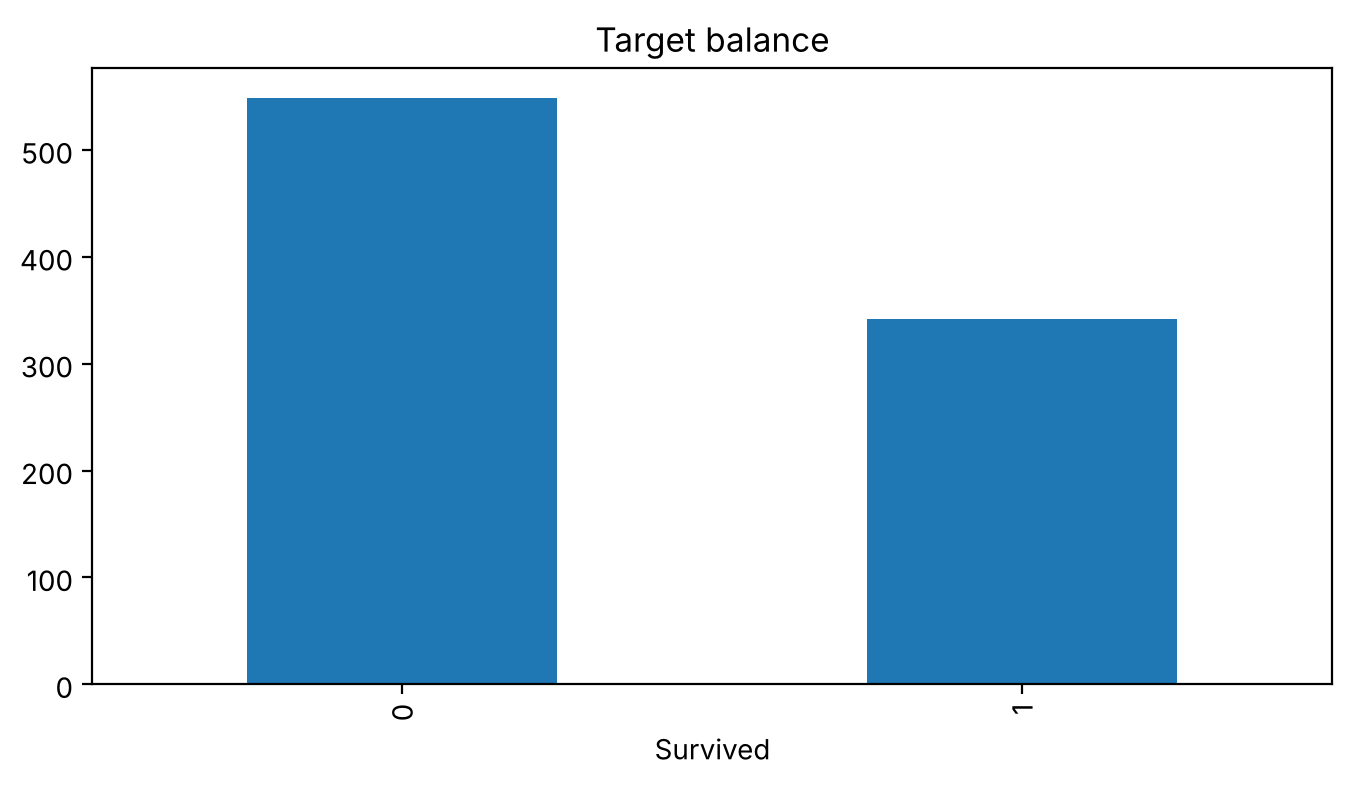

In [15]:
t = data[cfg['target']]
if cfg['task'] == 'classification':
    print(t.value_counts(normalize=True).round(3))
    t.value_counts().plot.bar(title='Target balance')
else:
    print(t.describe().round(1))
    t.plot.hist(bins=50, title='Target distribution')
plt.show()

### B3 · X, y and the split

In [16]:
data = data.drop_duplicates() if data.duplicated().sum() else data
Xb = data.drop(columns=[cfg['target']] + cfg['drop'])
yb = (data[cfg['target']] == cfg['positive']).astype(int) if cfg['task'] == 'classification' else data[cfg['target']]

num_b = Xb.select_dtypes(include='number').columns.tolist()
cat_b = [c for c in Xb.columns if c not in num_b]
print('Numeric:', num_b); print('Categorical:', cat_b)

Xb_train, Xb_test, yb_train, yb_test = train_test_split(
    Xb, yb, test_size=0.2, random_state=42,
    stratify=yb if cfg['task'] == 'classification' else None)
print('Train', Xb_train.shape, '| Test', Xb_test.shape)

Numeric: ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
Categorical: ['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked']
Train (712, 10) | Test (179, 10)


### B4 · Baseline inside a pipeline

In [17]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

pre_b = ColumnTransformer([
    ('num', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), num_b),
    ('cat', make_pipeline(SimpleImputer(strategy='most_frequent'), OneHotEncoder(handle_unknown='ignore')), cat_b)])

if cfg['task'] == 'classification':
    base = make_pipeline(pre_b, DummyClassifier(strategy='most_frequent')).fit(Xb_train, yb_train)
    pred = base.predict(Xb_test)
    print(f"Baseline accuracy: {accuracy_score(yb_test, pred):.3f}   recall: {recall_score(yb_test, pred):.3f}")
else:
    base = make_pipeline(pre_b, DummyRegressor(strategy='mean')).fit(Xb_train, yb_train)
    pred = base.predict(Xb_test)
    print(f"Baseline MAE: {mean_absolute_error(yb_test, pred):,.0f}   RMSE: {np.sqrt(mean_squared_error(yb_test, pred)):,.0f}")

Baseline accuracy: 0.615   recall: 0.000


### B5 · (Optional) A one-line rule baseline
Think of a simple rule from common sense (e.g. Titanic: *women survived*; housing: *predict the median price of the same ocean_proximity*). Does it beat the dummy baseline?

In [18]:
# TODO: write your rule. Example for Titanic:
if TEAM_DATASET == 'titanic':
    rule = (Xb_test['Sex'] == 'female').astype(int)
    print(f"Rule 'women survive': accuracy {accuracy_score(yb_test, rule):.3f}, recall {recall_score(yb_test, rule):.3f}")

Rule 'women survive': accuracy 0.777, recall 0.652


---
## Session 1 deliverables (edit this cell; double-click to type)

**Team:** …  **Dataset:** …

**1. Problem statement**
We want to predict **…** for **…** using **…** (available at prediction time), so that **…** can **…**. We measure success with **…** and must beat **…**.

**2. Dataset description:** rows …, columns …, numeric …, categorical …, missing values in … because …

**3. Target balance / distribution:** …

**4. Split:** method …, reason …, `random_state=42`, train … rows, test … rows

**5. Baseline:** metric …, score …. Why this metric: …

**6. Leakage note** (at least two):
- Risk 1: … → what we did: …
- Risk 2: … → what we did: …

> **TA checkpoint:** be ready to answer: *Why this metric? Why this split? Which column worried you most, and why?*